In [1]:
import os
import json
import time
import hashlib
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, FunctionTransformer

from sklearn.metrics import (
    root_mean_squared_error,
    mean_absolute_error,
    median_absolute_error,
    r2_score
)

from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

In [2]:
DATA_PATH = "../data/processed/sparcs_2024_final.parquet"

df = pd.read_parquet(DATA_PATH).reset_index(drop=True)

POST_ADMISSION = [
    "ccsr_diagnosis_code",
    "apr_medical_surgical",
    "ccsr_procedure_code"
]

TARGET = "los"

# Admission features only
ADMISSION = [
    col for col in df.columns
    if col not in POST_ADMISSION + [TARGET]
]

ORDINAL_FTRS = ["age_group"]

ORDINAL_CATS = [
    ["0-17", "18-29", "30-49", "50-69", "70 or Older"]
]

CATEGORICAL_FTRS = [
    col for col in ADMISSION + POST_ADMISSION
    if col not in ORDINAL_FTRS
]

CONTINUOUS_FTRS = []

# EXPERIMENT SETTINGS

PCT = 0.01
N_STATES = 5
N_FOLDS = 5
TEST_SIZE = 0.005
RANDOM_STATE = 42
LOS_BINS = [0, 1, 2, 3, 5, 7, 14, 30, 120]

# OUTPUT DIRECTORIES
OUTPUT_DIR = "../results/los_learning_curve"

SPLIT_DIR = os.path.join(OUTPUT_DIR, "shared")
MODEL_DIR = os.path.join(OUTPUT_DIR, "models")
RESULT_DIR = os.path.join(OUTPUT_DIR, "results")
PREDICTION_DIR = os.path.join(OUTPUT_DIR, "predictions")

for folder in [
    SPLIT_DIR,
    MODEL_DIR,
    RESULT_DIR,
    PREDICTION_DIR
]:
    os.makedirs(folder, exist_ok=True)


# Basic checks
X = df[ADMISSION].copy()
y = df[TARGET].copy()

assert y.notna().all(), "The target contains missing values."
assert X.columns.tolist() == ADMISSION

print("Dataset shape:", df.shape)
print("Number of admission features:", len(ADMISSION))
print("Admission features:", ADMISSION)
print("Target:", TARGET)
print("Output directory:", OUTPUT_DIR)

Dataset shape: (1993483, 15)
Number of admission features: 11
Admission features: ['permanent_facility_id', 'age_group', 'zip_code', 'gender', 'race', 'ethnicity', 'type_of_admission', 'payment_typology_1', 'emergency_department_indicator', 'payment_typology_2', 'payment_typology_3']
Target: los
Output directory: ../results/los_learning_curve


In [3]:
def get_los_bins(y):
    #Assign LOS observations to stratification bins.
    bins = pd.cut(y, bins=LOS_BINS, labels=False, include_lowest=True)
    if bins.isna().any():
        raise ValueError(
            "Some LOS values fall outside LOS_BINS. "
            "Check the target range and bin boundaries."
        )

    return bins

def get_data_fingerprint(path):
    #Generate a SHA256 fingerprint of the source dataset.
    sha256 = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha256.update(chunk)

    return sha256.hexdigest()

DATA_FINGERPRINT = get_data_fingerprint(DATA_PATH)

In [4]:
SPLIT_PATH = os.path.join(SPLIT_DIR, "fixed_test_split.joblib")

if not os.path.exists(SPLIT_PATH):
    print("Creating fixed train/test split...")
    indices = np.arange(len(df))
    train_idx, test_idx = train_test_split(
        indices,
        test_size=TEST_SIZE,
        stratify=get_los_bins(y),
        random_state=RANDOM_STATE
    )
    split_data = {
        "train_idx": train_idx,
        "test_idx": test_idx,
        "data_fingerprint": DATA_FINGERPRINT,
        "feature_columns": ADMISSION,
        "target": TARGET,
        "test_size": TEST_SIZE,
        "random_state": RANDOM_STATE
    }

    joblib.dump(split_data, SPLIT_PATH)
    print("Fixed split saved.")

else:
    print("Loading existing fixed test split...")
    split_data = joblib.load(SPLIT_PATH)
    assert split_data["data_fingerprint"] == DATA_FINGERPRINT, (
        "The dataset does not match the dataset used to create "
        "the existing fixed split."
    )
    assert split_data["feature_columns"] == ADMISSION
    assert split_data["target"] == TARGET

train_idx = split_data["train_idx"]
test_idx = split_data["test_idx"]

X_train_val = X.iloc[train_idx].copy()
y_train_val = y.iloc[train_idx].copy()

X_test = X.iloc[test_idx].copy()
y_test = y.iloc[test_idx].copy()

print("Train + validation:", X_train_val.shape)
print("Test:", X_test.shape)

print(
    f"Actual test percentage: "
    f"{len(X_test) / len(df):.3%}"
)

Loading existing fixed test split...
Train + validation: (1983515, 11)
Test: (9968, 11)
Actual test percentage: 0.500%


In [5]:
def create_subset(y_train_val, pct, random_state=RANDOM_STATE):
    #Create a nested, stratified subset of train_val.
    rng = np.random.default_rng(random_state)
    train_bins = get_los_bins(y_train_val).to_numpy()
    selected = []
    for bin_label in np.unique(train_bins):
        idx = np.where(train_bins == bin_label)[0]
        shuffled_idx = rng.permutation(idx)
        n_select = max(1, int(round(len(idx) * pct)))
        selected.extend(shuffled_idx[:n_select])

    return np.array(selected, dtype=int)

In [6]:
def make_preprocessor(features, interaction_ftrs=None):
    if interaction_ftrs is None:
        interaction_ftrs = []
    ordinal_features = [col for col in features if col in ORDINAL_FTRS]
    onehot_features = [col for col in features if col not in ORDINAL_FTRS] + interaction_ftrs
    transformers = []
    if ordinal_features:
        ordinal_categories = [ORDINAL_CATS[ORDINAL_FTRS.index(col)] for col in ordinal_features]
        transformers.append(("ordinal", OrdinalEncoder(categories=ordinal_categories,
                                                       handle_unknown="use_encoded_value", 
                                                       unknown_value=-1), ordinal_features))
    if onehot_features:
        transformers.append(("onehot", OneHotEncoder(handle_unknown="ignore"), onehot_features))
        
    return ColumnTransformer(transformers=transformers, remainder="drop")

In [7]:
def build_model(model_name, features, interaction_ftrs=None, random_state=RANDOM_STATE):

    if interaction_ftrs is None:
        interaction_ftrs = []

    model_features = features + interaction_ftrs

    if model_name == "svr":

        model = Pipeline([
            ("preprocessor", make_preprocessor(features, interaction_ftrs)),
            ("model", SVR())
        ])

        param_grid = {
            "model__C": [0.1, 1, 10],
            "model__epsilon": [0.1, 0.5, 1.0],
            "model__kernel": ["rbf"]
        }

    elif model_name == "lightgbm":

        model = Pipeline([
            ("preprocessor", make_preprocessor(features, interaction_ftrs)),
            ("model", LGBMRegressor(
                random_state=random_state,
                n_jobs=1,
                verbosity=-1
            ))
        ])

        param_grid = {
            "model__n_estimators": [100, 300, 500],
            "model__num_leaves": [15, 31],
            "model__learning_rate": [0.05, 0.07, 0.1]
        }

    elif model_name == "catboost":

        model = CatBoostRegressor(
            random_seed=random_state,
            verbose=0,
            thread_count=1,
            iterations=2000,
            early_stopping_rounds=50,
            allow_writing_files=False
        )

        param_grid = {
            "depth": [4, 6],
            "learning_rate": [0.03, 0.07, 0.1],
            "l2_leaf_reg": [3, 5]
        }

    elif model_name == "knn":

        model = Pipeline([
            ("preprocessor", make_preprocessor(features, interaction_ftrs)),
            ("model", KNeighborsRegressor(
                algorithm="brute",
                n_jobs=1
            ))
        ])

        param_grid = {
            "model__n_neighbors": [5, 10, 20, 40],
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2]
        }

    else:
        raise ValueError(f"Unknown model: {model_name}")

    return model, param_grid

In [8]:
def calculate_metrics(y_true, y_pred):
    return {
        "rmse": root_mean_squared_error(y_true, y_pred),
        "mae": mean_absolute_error(y_true, y_pred),
        "median_ae": median_absolute_error(y_true, y_pred),
        "r2": r2_score(y_true, y_pred)
    }

In [9]:
def cross_validation(model, param_grid, X_train, y_train, X_test, y_test, 
                     random_state=RANDOM_STATE,fit_params=None):
    kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=random_state)
    scoring = {
        "rmse": "neg_root_mean_squared_error",
        "mae": "neg_mean_absolute_error",
        "median_ae": "neg_median_absolute_error",
        "r2": "r2"
    }
    grid = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        scoring=scoring,
        refit="rmse",
        cv=kf,
        return_train_score=True,
        n_jobs=1
    )

    grid.fit(X_train, y_train, **(fit_params or {}))

    best_model = grid.best_estimator_
    best_idx = grid.best_index_

    cv_metrics = {
        "rmse": -grid.cv_results_["mean_test_rmse"][best_idx],
        "mae": -grid.cv_results_["mean_test_mae"][best_idx],
        "median_ae": -grid.cv_results_["mean_test_median_ae"][best_idx],
        "r2": grid.cv_results_["mean_test_r2"][best_idx]
    }

    test_predictions = best_model.predict(X_test)
    test_metrics = calculate_metrics(y_test, test_predictions)

    return (best_model, grid.best_params_, cv_metrics,
            test_metrics, test_predictions)

In [10]:
def get_experiment_suffix(use_interactions):
    return "interactions" if use_interactions else "no_interactions"

def save_model(best_model, model_name, pct, use_interactions, best_params,
               cv_metrics, test_metrics, model_features, interaction_ftrs, random_state):
    
    algorithm_dir = os.path.join(MODEL_DIR, model_name)
    os.makedirs(algorithm_dir, exist_ok=True)
    suffix = get_experiment_suffix(use_interactions)
    filename = (f"{model_name}_pct_{pct:.3f}_{suffix}_seed_{random_state}.joblib")

    model_path = os.path.join(algorithm_dir, filename)
    joblib.dump(best_model, model_path)

    metadata = {
        "algorithm": model_name,
        "pct": pct,
        "use_interactions": use_interactions,
        "features": model_features,
        "interaction_features": interaction_ftrs,
        "best_params": {
            key: str(value)
            for key, value in best_params.items()
        },
        "cv_metrics": cv_metrics,
        "test_metrics": test_metrics,
        "data_fingerprint": DATA_FINGERPRINT,
        "test_random_state": RANDOM_STATE,
        "subset_random_state": random_state,
        "cv_random_state": random_state,
        "n_folds": N_FOLDS,
        "model_path": model_path
    }

    metadata_path = model_path.replace(".joblib", "_metadata.json")

    with open(metadata_path, "w") as f:
        json.dump(metadata, f, indent=4)

    return model_path

In [11]:
RESULT_COLUMNS = [
    "algorithm",
    "pct",
    "use_interactions",
    "interaction_features",
    "n_train",
    "n_test",
    "actual_pct_train_val",
    "actual_pct_original",

    "cv_rmse",
    "cv_mae",
    "cv_median_ae",
    "cv_r2",

    "test_rmse",
    "test_mae",
    "test_median_ae",
    "test_r2",

    "best_params",
    "training_time_sec",
    "model_path",
    "prediction_path",

    "test_random_state",
    "subset_random_state",
    "cv_random_state",
    "data_fingerprint"
]


def save_result(result):
    model_name = result["algorithm"]
    result_path = os.path.join(RESULT_DIR, f"results_{model_name}.csv")

    new_result = pd.DataFrame([result])

    if os.path.exists(result_path):

        old_results = pd.read_csv(result_path)

        same_experiment = (np.isclose(old_results["pct"].astype(float),
                                      result["pct"])&
                           (old_results["use_interactions"].astype(str)
                            == str(result["use_interactions"]))&
                           (old_results["test_random_state"].astype(int)
                            == int(result["test_random_state"]))&
                           (old_results["subset_random_state"].astype(int)
                            == int(result["subset_random_state"]))&
                           (old_results["cv_random_state"].astype(int)
                            == int(result["cv_random_state"])))

        old_results = old_results.loc[~same_experiment]

        results = pd.concat([old_results, new_result], ignore_index=True)

    else:
        results = new_result

    results = results[RESULT_COLUMNS].sort_values(["pct", "use_interactions", "subset_random_state"])

    results.to_csv(result_path, index=False)

    return result_path

In [12]:
def run_experiment(model_name, pct, features=ADMISSION, 
                   use_interactions=False, random_state=RANDOM_STATE):
    """
    Train one algorithm at one PCT.

    Parameters
    ----------
    model_name : str
        "svr", "lightgbm", "catboost", or "knn".

    pct : float
        Training percentage of train_val.

    features : list
        Features to use.

    use_interactions : bool
        Whether to create interaction features.

    random_state : int
        Controls subset sampling and CV reproducibility.

    Saves
    -----
    Fitted model, metadata, predictions, and result CSV.
    """

    print("\n" + "=" * 75)
    print(f"Algorithm: {model_name.upper()}")
    print(f"Training PCT: {pct:.1%}")
    print(f"Interactions: {use_interactions}")
    print("=" * 75)

    # Select features and optionally add interactions
    X_all = df[features].copy()
    if use_interactions:
        X_all, interaction_ftrs = add_interactions(X_all, features)
    else:
        interaction_ftrs = []
        
    model_features = features + interaction_ftrs

    # Use the same fixed split for every experiment
    X_train_val = X_all.iloc[train_idx].copy()
    X_test_model = X_all.iloc[test_idx].copy()

    y_train_val = y.iloc[train_idx].copy()
    y_test = y.iloc[test_idx].copy()

    # Create the reproducible training subset
    subset_idx = create_subset(y_train_val, pct,
                               random_state=random_state)

    X_train = X_train_val.iloc[subset_idx].copy()
    y_train = y_train_val.iloc[subset_idx].copy()

    actual_pct_train_val = len(X_train) / len(X_train_val)
    actual_pct_original = len(X_train) / len(df)

    print(f"Training observations: {len(X_train):,}")
    print(f"Test observations: {len(X_test_model):,}")
    print(f"Actual train_val percentage: {actual_pct_train_val:.2%}")
    print(f"Actual original-data percentage: {actual_pct_original:.2%}")

    print(f"Features used: {len(model_features)}")
    print(f"Interaction features: {interaction_ftrs or 'None'}")

    # Build model and parameter grid

    model, param_grid = build_model(
        model_name=model_name,
        features=features,
        interaction_ftrs=interaction_ftrs,
        random_state=random_state)

    fit_params = {}

    if model_name == "catboost":
        fit_params["cat_features"] = model_features

    # Cross-validation and hyperparameter tuning
    start_time = time.time()

    (   best_model,
        best_params,
        cv_metrics,
        test_metrics,
        test_predictions
    ) = cross_validation(
        model=model,
        param_grid=param_grid,
        X_train=X_train,
        y_train=y_train,
        X_test=X_test_model,
        y_test=y_test,
        random_state=random_state,
        fit_params=fit_params
    )

    elapsed = time.time() - start_time

    # Save fitted model
    model_path = save_model(
        best_model=best_model,
        model_name=model_name,
        pct=pct,
        use_interactions=use_interactions,
        best_params=best_params,
        cv_metrics=cv_metrics,
        test_metrics=test_metrics,
        model_features=model_features,
        interaction_ftrs=interaction_ftrs,
        random_state=random_state
    )

    # Save test predictions
    suffix = get_experiment_suffix(use_interactions)
    prediction_filename = (f"{model_name}_pct_{pct:.3f}_{suffix}_seed_{random_state}_predictions.csv")
    prediction_path = os.path.join(PREDICTION_DIR, prediction_filename)

    predictions_df = pd.DataFrame({
        "row_index": test_idx,
        "y_true": y_test.to_numpy(),
        "y_pred": np.asarray(test_predictions)
    })

    predictions_df["residual"] = (predictions_df["y_true"] - predictions_df["y_pred"])
    predictions_df["absolute_error"] = (predictions_df["residual"].abs())
    predictions_df["random_state"] = random_state

    predictions_df.to_csv(prediction_path, index=False)
    
    # Build result record
    result = {
        "algorithm": model_name,
        "pct": pct,
        "use_interactions": use_interactions,
        "interaction_features": json.dumps(interaction_ftrs),
        "n_train": len(X_train),
        "n_test": len(X_test_model),
        "actual_pct_train_val": actual_pct_train_val,
        "actual_pct_original": actual_pct_original,

        "cv_rmse": cv_metrics["rmse"],
        "cv_mae": cv_metrics["mae"],
        "cv_median_ae": cv_metrics["median_ae"],
        "cv_r2": cv_metrics["r2"],

        "test_rmse": test_metrics["rmse"],
        "test_mae": test_metrics["mae"],
        "test_median_ae": test_metrics["median_ae"],
        "test_r2": test_metrics["r2"],

        "best_params": json.dumps(best_params, default=str),
        "training_time_sec": elapsed,
        "model_path": model_path,
        "prediction_path": prediction_path,

        "test_random_state": RANDOM_STATE,
        "subset_random_state": random_state,
        "cv_random_state": random_state,
        "data_fingerprint": DATA_FINGERPRINT
    }

    # Save results
    result_path = save_result(result)
    
    # Print summary
    print("\nCross-validation metrics:")
    for metric, value in cv_metrics.items():
        print(f"{metric.upper():<12}: {value:.4f}")

    print("\nTest metrics:")
    for metric, value in test_metrics.items():
        print(f"{metric.upper():<12}: {value:.4f}")

    print(f"\nTraining time: {elapsed / 60:.2f} minutes")
    print(f"Model saved: {model_path}")
    print(f"Predictions saved: {prediction_path}")
    print(f"Results saved: {result_path}")

    return best_model, result

In [19]:
PCT_TO_RUN = 0.003

ALGORITHMS_TO_RUN = [
    "lightgbm",
    "knn",
    "svr",
]

USE_INTERACTIONS = False

# Store the original seed for reference.
# Do NOT include it in the new runs.
ORIGINAL_RANDOM_STATE = RANDOM_STATE

NEW_RANDOM_STATES = [1024, 2026]

In [20]:
all_new_results = []

for seed in NEW_RANDOM_STATES:

    print(f"\n{'#' * 80}")
    print(f"RUNNING EXPERIMENTS WITH RANDOM STATE: {seed}")
    print(f"{'#' * 80}")

    current_results = []

    for algorithm in ALGORITHMS_TO_RUN:

        best_model, result = run_experiment(
            model_name=algorithm,
            pct=PCT_TO_RUN,
            features=ADMISSION,
            use_interactions=USE_INTERACTIONS,
            random_state=seed
        )

        current_results.append(result)

    current_results_df = pd.DataFrame(current_results)

    all_new_results.append(current_results_df)

# Combine results from all NEW random states
all_new_results_df = pd.concat(all_new_results, ignore_index=True)
all_new_results_df


################################################################################
RUNNING EXPERIMENTS WITH RANDOM STATE: 1024
################################################################################

Algorithm: LIGHTGBM
Training PCT: 0.3%
Interactions: False
Training observations: 5,951
Test observations: 9,968
Actual train_val percentage: 0.30%
Actual original-data percentage: 0.30%
Features used: 11
Interaction features: None

Cross-validation metrics:
RMSE        : 8.5649
MAE         : 4.5505
MEDIAN_AE   : 3.0766
R2          : 0.0154

Test metrics:
RMSE        : 8.6639
MAE         : 4.5538
MEDIAN_AE   : 3.0827
R2          : 0.0277

Training time: 1.30 minutes
Model saved: ../results/los_learning_curve\models\lightgbm\lightgbm_pct_0.003_no_interactions_seed_1024.joblib
Predictions saved: ../results/los_learning_curve\predictions\lightgbm_pct_0.003_no_interactions_seed_1024_predictions.csv
Results saved: ../results/los_learning_curve\results\results_lightgbm.csv

Algorithm: KN

,algorithm,pct,use_interactions,interaction_features,n_train,n_test,actual_pct_train_val,actual_pct_original,cv_rmse,cv_mae,...,test_median_ae,test_r2,best_params,training_time_sec,model_path,prediction_path,test_random_state,subset_random_state,cv_random_state,data_fingerprint
0,lightgbm,0.003,False,[],5951,9968,0.003,0.002985,8.564886,4.550452,...,3.082695,0.027681,"{""model__learning_rate"": 0.05, ""model__n_estim...",78.200560,../results/los_learning_curve\models\lightgbm\...,../results/los_learning_curve\predictions\ligh...,42,1024,1024,7b660240b4ca3799b9a9ceff81ed2bf20fccb17a9bd994...
1,knn,0.003,False,[],5951,9968,0.003,0.002985,8.569586,4.480079,...,3.000000,0.018835,"{""model__n_neighbors"": 40, ""model__p"": 2, ""mod...",214.605090,../results/los_learning_curve\models\knn\knn_p...,../results/los_learning_curve\predictions\knn_...,42,1024,1024,7b660240b4ca3799b9a9ceff81ed2bf20fccb17a9bd994...
2,svr,0.003,False,[],5951,9968,0.003,0.002985,8.690988,3.966042,...,2.003736,-0.015109,"{""model__C"": 10, ""model__epsilon"": 1.0, ""model...",882.679718,../results/los_learning_curve\models\svr\svr_p...,../results/los_learning_curve\predictions\svr_...,42,1024,1024,7b660240b4ca3799b9a9ceff81ed2bf20fccb17a9bd994...
3,lightgbm,0.003,False,[],5951,9968,0.003,0.002985,9.180128,4.737188,...,3.156369,0.022360,"{""model__learning_rate"": 0.05, ""model__n_estim...",120.254322,../results/los_learning_curve\models\lightgbm\...,../results/los_learning_curve\predictions\ligh...,42,2026,2026,7b660240b4ca3799b9a9ceff81ed2bf20fccb17a9bd994...
4,knn,0.003,False,[],5951,9968,0.003,0.002985,9.207335,4.616299,...,3.000000,0.018134,"{""model__n_neighbors"": 40, ""model__p"": 2, ""mod...",295.913804,../results/los_learning_curve\models\knn\knn_p...,../results/los_learning_curve\predictions\knn_...,42,2026,2026,7b660240b4ca3799b9a9ceff81ed2bf20fccb17a9bd994...
5,svr,0.003,False,[],5951,9968,0.003,0.002985,9.393818,4.132573,...,2.013421,-0.013531,"{""model__C"": 10, ""model__epsilon"": 1.0, ""model...",454.132041,../results/los_learning_curve\models\svr\svr_p...,../results/los_learning_curve\predictions\svr_...,42,2026,2026,7b660240b4ca3799b9a9ceff81ed2bf20fccb17a9bd994...


In [15]:
def load_algorithm_results(model_name):
    result_path = os.path.join(RESULT_DIR, f"results_{model_name}.csv")
    if not os.path.exists(result_path):
        print(f"No results found for {model_name}.")
        return pd.DataFrame()
    return pd.read_csv(result_path)

svr_results = load_algorithm_results("svr")
lightgbm_results = load_algorithm_results("lightgbm")
#catboost_results = load_algorithm_results("catboost")
knn_results = load_algorithm_results("knn")

In [16]:
svr_results[
    [
        "pct",
        "n_train",
        "cv_rmse",
        "test_rmse",
        "test_mae",
        "test_median_ae",
        "test_r2",
        "training_time_sec"
    ]
]

,pct,n_train,cv_rmse,test_rmse,test_mae,test_median_ae,test_r2,training_time_sec
0,0.001,1983,8.734280,8.882186,4.045045,2.089471,-0.021924,69.464950
1,0.001,1983,9.208922,8.869063,4.064111,2.103183,-0.018906,55.317169
2,0.001,1983,9.435985,8.880478,4.067420,2.099881,-0.021531,57.725576
3,0.002,3968,8.729748,8.885461,4.014427,2.000190,-0.022677,319.457340
4,0.003,5951,8.876164,8.880452,4.002227,2.000248,-0.021525,574.814864
5,0.004,7933,8.926264,8.863987,3.998312,1.999910,-0.017740,772.570528
6,0.005,9916,8.866735,8.860434,3.981054,1.999714,-0.016925,1366.144473
7,0.006,11901,9.043744,8.850655,3.966777,1.983193,-0.014681,2247.823241
8,0.007,13884,8.929820,8.847568,3.963722,1.995584,-0.013973,3061.261676
9,0.008,15869,8.879646,8.830306,3.953376,1.986468,-0.010021,3989.385166


In [27]:
my_results = pd.concat(
    [
        load_algorithm_results("svr"),
        load_algorithm_results("lightgbm"),
        #load_algorithm_results("catboost"),
        load_algorithm_results("knn")
    ],
    ignore_index=True
)

my_results = my_results.sort_values(["pct", "algorithm"]).reset_index(drop=True)
my_results

,algorithm,pct,use_interactions,interaction_features,n_train,n_test,actual_pct_train_val,actual_pct_original,cv_rmse,cv_mae,...,test_median_ae,test_r2,best_params,training_time_sec,model_path,prediction_path,test_random_state,subset_random_state,cv_random_state,data_fingerprint
0,knn,0.001,False,[],1983,9968,0.001000,0.000995,8.559236,4.462959,...,3.050000,0.016908,"{""model__n_neighbors"": 40, ""model__p"": 2, ""mod...",51.869204,../results/los_learning_curve\models\knn\knn_p...,../results/los_learning_curve\predictions\knn_...,42,42,42,7b660240b4ca3799b9a9ceff81ed2bf20fccb17a9bd994...
1,lightgbm,0.001,False,[],1983,9968,0.001000,0.000995,8.729356,4.689664,...,3.094680,0.015888,"{""model__learning_rate"": 0.05, ""model__n_estim...",70.259642,../results/los_learning_curve\models\lightgbm\...,../results/los_learning_curve\predictions\ligh...,42,42,42,7b660240b4ca3799b9a9ceff81ed2bf20fccb17a9bd994...
2,svr,0.001,False,[],1983,9968,0.001000,0.000995,8.734280,4.054468,...,2.089471,-0.021924,"{""model__C"": 10, ""model__epsilon"": 1.0, ""model...",69.464950,../results/los_learning_curve\models\svr\svr_p...,../results/los_learning_curve\predictions\svr_...,42,42,42,7b660240b4ca3799b9a9ceff81ed2bf20fccb17a9bd994...
3,knn,0.002,False,[],3968,9968,0.002000,0.001990,8.527735,4.491653,...,3.000000,0.013783,"{""model__n_neighbors"": 40, ""model__p"": 2, ""mod...",168.021845,../results/los_learning_curve\models\knn\knn_p...,../results/los_learning_curve\predictions\knn_...,42,42,42,7b660240b4ca3799b9a9ceff81ed2bf20fccb17a9bd994...
4,lightgbm,0.002,False,[],3968,9968,0.002000,0.001990,8.608664,4.609109,...,3.045939,0.022899,"{""model__learning_rate"": 0.05, ""model__n_estim...",129.470765,../results/los_learning_curve\models\lightgbm\...,../results/los_learning_curve\predictions\ligh...,42,42,42,7b660240b4ca3799b9a9ceff81ed2bf20fccb17a9bd994...
5,svr,0.002,False,[],3968,9968,0.002000,0.001990,8.729748,4.007343,...,2.000190,-0.022677,"{""model__C"": 10, ""model__epsilon"": 1.0, ""model...",319.457340,../results/los_learning_curve\models\svr\svr_p...,../results/los_learning_curve\predictions\svr_...,42,42,42,7b660240b4ca3799b9a9ceff81ed2bf20fccb17a9bd994...
6,knn,0.003,False,[],5951,9968,0.003000,0.002985,8.692590,4.526376,...,3.175000,-0.001667,"{""model__n_neighbors"": 40, ""model__p"": 2, ""mod...",233.295310,../results/los_learning_curve\models\knn\knn_p...,../results/los_learning_curve\predictions\knn_...,42,42,42,7b660240b4ca3799b9a9ceff81ed2bf20fccb17a9bd994...
7,lightgbm,0.003,False,[],5951,9968,0.003000,0.002985,8.646067,4.581969,...,3.063571,0.019945,"{""model__learning_rate"": 0.07, ""model__n_estim...",170.667465,../results/los_learning_curve\models\lightgbm\...,../results/los_learning_curve\predictions\ligh...,42,42,42,7b660240b4ca3799b9a9ceff81ed2bf20fccb17a9bd994...
8,svr,0.003,False,[],5951,9968,0.003000,0.002985,8.876164,3.996554,...,2.000248,-0.021525,"{""model__C"": 10, ""model__epsilon"": 1.0, ""model...",574.814864,../results/los_learning_curve\models\svr\svr_p...,../results/los_learning_curve\predictions\svr_...,42,42,42,7b660240b4ca3799b9a9ceff81ed2bf20fccb17a9bd994...
9,knn,0.004,False,[],7933,9968,0.003999,0.003979,8.755050,4.542642,...,3.025000,0.017309,"{""model__n_neighbors"": 40, ""model__p"": 2, ""mod...",501.939862,../results/los_learning_curve\models\knn\knn_p...,../results/los_learning_curve\predictions\knn_...,42,42,42,7b660240b4ca3799b9a9ceff81ed2bf20fccb17a9bd994...


In [28]:
def plot_learning_curve(results, metric="test_rmse", title=None):
    """
    Plot mean performance against training percentage.
    Error bars represent standard deviation across random states.
    Only plots experiments with the same interaction setting.
    """
    if results.empty:
        print("No results available.")
        return

    plt.figure(figsize=(10, 6))

    for algorithm in sorted(results["algorithm"].unique()):

        data = results[(results["algorithm"] == algorithm) &
            (results["use_interactions"] == False)]

        if data.empty:
            continue
            
        summary = (data.groupby("pct")[metric]
                       .agg(["mean", "std"])
                       .reset_index()
                       .sort_values("pct")
                  )

        plt.errorbar(
            summary["pct"] * 100,
            summary["mean"],
            yerr=summary["std"].fillna(0),
            marker="o",
            capsize=4,
            label=algorithm.upper()
        )

    plt.xlabel("Training Data Percentage (%)")
    plt.ylabel(metric.replace("_", " ").upper())
    plt.title(title if title else f"Learning Curve - {metric.upper()}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

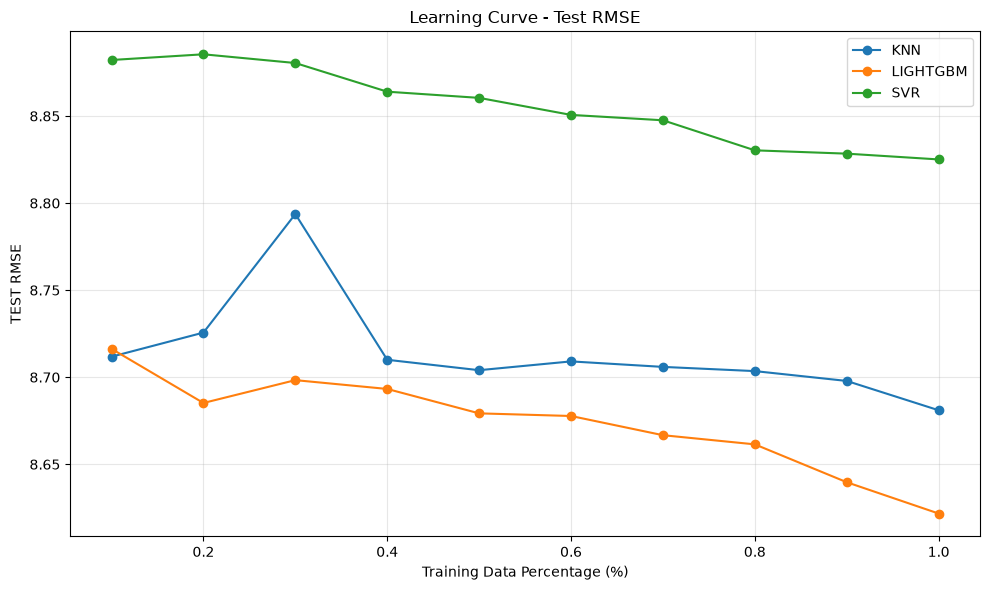

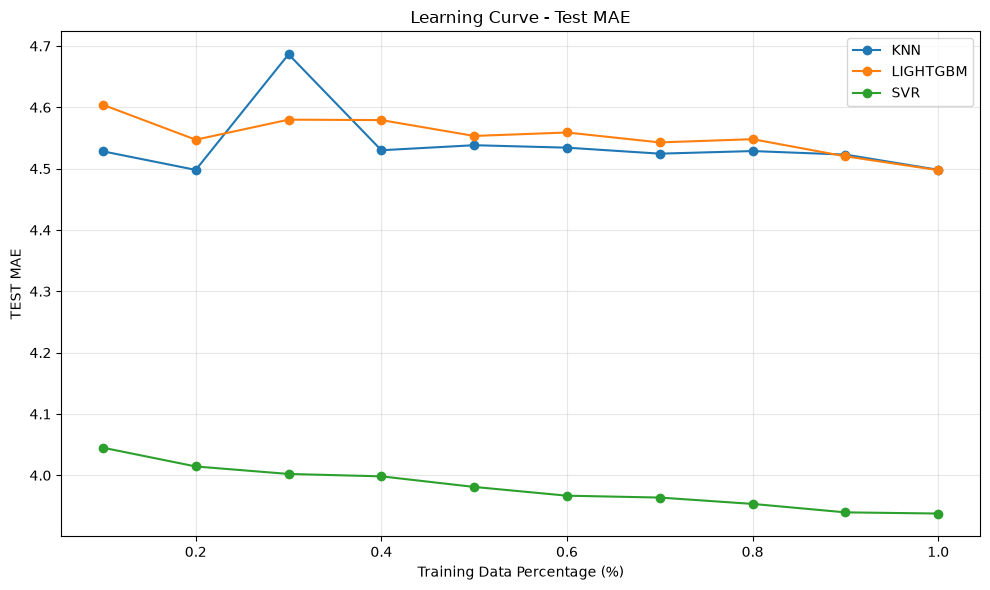

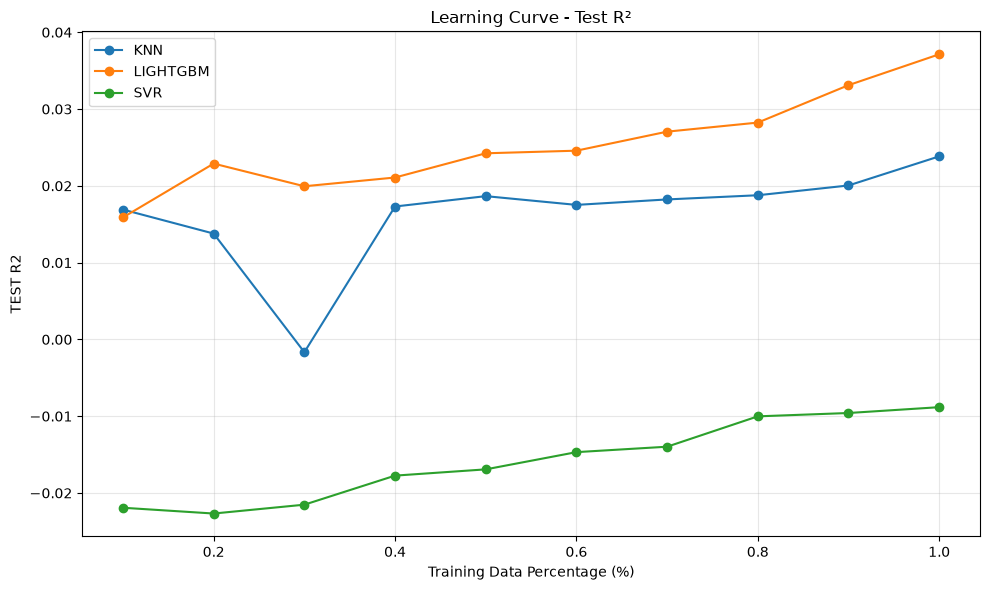

In [29]:
plot_learning_curve(
    my_results,
    metric="test_rmse",
    title="Learning Curve - Test RMSE"
)

plot_learning_curve(
    my_results,
    metric="test_mae",
    title="Learning Curve - Test MAE"
)

plot_learning_curve(
    my_results,
    metric="test_r2",
    title="Learning Curve - Test R²"
)